In [3]:
# Core packages
import numpy as np
import pandas as pd
import skfuzzy as fuzz
from skfuzzy import control as ctrl
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# For Genetic Algorithm
import random

# Set random seed for reproducibility
np.random.seed(42)
random.seed(42)


In [4]:
file_path = r"..\data\processed\healthcare_processed.csv"
fuzzy_data = pd.read_csv(file_path)
# fuzzy_data.head()

# Define features and target
X_fuzzy = fuzzy_data[['age', 'bmi','gender','ever_married','work_type','smoking_status', 'avg_glucose_level', 'hypertension', 'heart_disease', 'Residence_type']]
y_fuzzy = fuzzy_data['stroke_risk']  # 0=Low, 1=Medium, 2=High


In [5]:
# Numeric features
age = ctrl.Antecedent(np.arange(0, 1.01, 0.01), 'age')
bmi = ctrl.Antecedent(np.arange(0, 1.01, 0.01), 'bmi')
avg_glucose = ctrl.Antecedent(np.arange(0, 1.01, 0.01), 'avg_glucose_level')

# Binary features
hypertension = ctrl.Antecedent(np.arange(0, 2, 1), 'hypertension')
heart_disease = ctrl.Antecedent(np.arange(0, 2, 1), 'heart_disease')

# Categorical features
gender = ctrl.Antecedent(np.arange(0, 3, 1), 'gender')
ever_married = ctrl.Antecedent(np.arange(0, 2, 1), 'ever_married')
work_type = ctrl.Antecedent(np.arange(0, 5, 1), 'work_type')
smoking_status = ctrl.Antecedent(np.arange(0, 4, 1), 'smoking_status')
Residence_type = ctrl.Antecedent(np.arange(0, 2, 1), 'Residence_type')

# Output
stroke_risk = ctrl.Consequent(np.arange(0, 3, 1), 'stroke_risk')


In [6]:
# Parameters per MF for triangular: 3 (left, center, right)
# Number of genes per feature set
genes_per_feature = {
    'age': 9,            # 3 MFs × 3 params
    'bmi': 9,
    'avg_glucose_level': 9,
    'hypertension': 6,   # 2 MFs × 3 params
    'heart_disease': 6,
    'gender': 9,         # 3 sets × 3
    'ever_married': 6,   # 2 sets × 3
    'work_type': 15,     # 5 sets × 3
    'smoking_status': 12,# 4 sets × 3
    'Residence_type': 6  # 2 sets × 3
}

# Total chromosome length
total_genes = sum(genes_per_feature.values())
print("Total genes per chromosome:", total_genes)

# Create initial population
population_size = 20
initial_population = []

for _ in range(population_size):
    # Random values between 0 and 1 for each gene
    chromosome = np.random.rand(total_genes)
    initial_population.append(chromosome)

# Convert to numpy array
initial_population = np.array(initial_population)
print("Initial population shape:", initial_population.shape)


Total genes per chromosome: 87
Initial population shape: (20, 87)


In [7]:
def decode_chromosome(chromosome, genes_per_feature):
    """
    Split chromosome genes into feature-specific MF parameter groups.
    Returns dict: {feature_name: list of MFs (each MF = [a, b, c])}
    """
    decoded = {}
    idx = 0

    for feature, n_genes in genes_per_feature.items():
        feature_genes = chromosome[idx: idx + n_genes]
        idx += n_genes

        # reshape to groups of 3 parameters (triangular MFs)
        mfs = feature_genes.reshape(-1, 3)
        
        # sort within each MF to keep order (a < b < c)
        mfs = np.sort(mfs, axis=1)
        
        decoded[feature] = mfs

    return decoded


In [8]:
# Take first chromosome and decode it
example_chromosome = initial_population[0]
decoded = decode_chromosome(example_chromosome, genes_per_feature)

for k, v in decoded.items():
    print(f"{k}: {v.shape}")


age: (3, 3)
bmi: (3, 3)
avg_glucose_level: (3, 3)
hypertension: (2, 3)
heart_disease: (2, 3)
gender: (3, 3)
ever_married: (2, 3)
work_type: (5, 3)
smoking_status: (4, 3)
Residence_type: (2, 3)


Step 5.1 — Defining Fitness Function

In [9]:
def evaluate_fitness(chromosome, X, y, genes_per_feature):
    """
    Evaluate fitness (accuracy) for a given chromosome.
    Simplified version: uses fuzzy-like scoring instead of full rule simulation.
    """
    decoded = decode_chromosome(chromosome, genes_per_feature)
    preds = []

    # Iterate over each row in dataset
    for _, row in X.iterrows():
        fuzzy_score = 0
        
        # Numeric features: use Gaussian-like similarity to MF centers
        for feature in ['age', 'bmi', 'avg_glucose_level']:
            mfs = decoded[feature]
            centers = mfs[:, 1]
            fuzzy_score += np.mean(np.exp(-((row[feature] - centers)**2) / 0.1))

        # Binary / categorical features: match based on closeness
        for feature in ['gender', 'ever_married', 'work_type', 
                        'smoking_status', 'hypertension', 
                        'heart_disease', 'Residence_type']:
            mfs = decoded[feature]
            centers = mfs[:, 1]
            fuzzy_score += np.mean(np.exp(-((row[feature] - centers)**2)))

        # Normalize score to range (0,3) roughly to simulate fuzzy risk
        risk_level = int(np.clip(fuzzy_score / 10, 0, 2))
        preds.append(risk_level)

    acc = accuracy_score(y, preds)
    return acc


In [10]:
# Test the function on one chromosome
fitness_score = evaluate_fitness(initial_population[0], X_fuzzy, y_fuzzy, genes_per_feature)
print("Example chromosome fitness:", round(fitness_score, 4))


Example chromosome fitness: 0.5431


In [11]:
# GA parameters
num_generations = 10        # عدد الأجيال (ممكن نزيده لاحقاً)
population_size = 20        # نفس عدد الكروموسومات الحالي
mutation_rate = 0.1         # احتمال التغيير العشوائي
elite_size = 4              # عدد أفضل الكروموسومات يلي بنحتفظ فيها كما هي


In [12]:
def select_elites(population, fitness_scores, elite_size):
    sorted_indices = np.argsort(fitness_scores)[::-1]  # ترتيب تنازلي
    elites = population[sorted_indices[:elite_size]]
    return elites


In [13]:
def crossover(parent1, parent2):
    point = np.random.randint(1, len(parent1) - 1)
    child1 = np.concatenate([parent1[:point], parent2[point:]])
    child2 = np.concatenate([parent2[:point], parent1[point:]])
    return child1, child2


In [14]:
def mutate(chromosome, mutation_rate):
    for i in range(len(chromosome)):
        if np.random.rand() < mutation_rate:
            chromosome[i] = np.clip(chromosome[i] + np.random.normal(0, 0.1), 0, 1)
    return chromosome


In [15]:
best_fitness_history = []

population = initial_population.copy()

for generation in range(num_generations):
    fitness_scores = []

    # تقييم كل كروموسوم
    for chromosome in population:
        score = evaluate_fitness(chromosome, X_fuzzy, y_fuzzy, genes_per_feature)
        fitness_scores.append(score)
    
    fitness_scores = np.array(fitness_scores)

    # حفظ أفضل نتيجة
    best_idx = np.argmax(fitness_scores)
    best_fitness = fitness_scores[best_idx]
    best_fitness_history.append(best_fitness)
    
    print(f"Generation {generation+1}/{num_generations} | Best Fitness: {best_fitness:.4f}")

    # اختيار النخبة (الأفضل)
    elites = select_elites(population, fitness_scores, elite_size)

    # إنشاء جيل جديد
    new_population = list(elites.copy())

    # نولد بقية الأفراد من crossover
    while len(new_population) < population_size:
        parents = random.sample(list(elites), 2)
        child1, child2 = crossover(parents[0], parents[1])
        new_population.append(mutate(child1, mutation_rate))
        if len(new_population) < population_size:
            new_population.append(mutate(child2, mutation_rate))
    
    # تحديث السكان
    population = np.array(new_population)


Generation 1/10 | Best Fitness: 0.5431
Generation 2/10 | Best Fitness: 0.5431
Generation 3/10 | Best Fitness: 0.5431
Generation 4/10 | Best Fitness: 0.5431
Generation 5/10 | Best Fitness: 0.5431
Generation 6/10 | Best Fitness: 0.5431
Generation 7/10 | Best Fitness: 0.5431
Generation 8/10 | Best Fitness: 0.5431
Generation 9/10 | Best Fitness: 0.5431
Generation 10/10 | Best Fitness: 0.5431


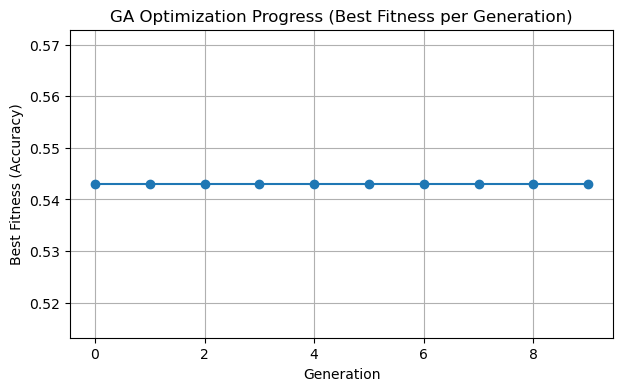

Best Fitness Achieved: 0.5431


In [16]:
# رسم منحنى تطور اللياقة عبر الأجيال
plt.figure(figsize=(7,4))
plt.plot(best_fitness_history, marker='o')
plt.title("GA Optimization Progress (Best Fitness per Generation)")
plt.xlabel("Generation")
plt.ylabel("Best Fitness (Accuracy)")
plt.grid(True)
plt.show()

# أفضل كروموسوم بعد آخر جيل
best_chromosome = population[np.argmax(fitness_scores)]
print("Best Fitness Achieved:", round(max(best_fitness_history), 4))
